# Library Import

In [1]:
import os
import zipfile
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms.v2 as transforms

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
)

# Data Import & Read

In [2]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames[:3]: 
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/test.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png
/kaggle/input/competitions/aptos2019-blindness-detection/test_images/755615db51d3.png
/kaggle/input/competitions/aptos2019-blindness-detection/test_images/d8f6c660bf2d.png
/kaggle/input/competitions/aptos2019-blindness-detection/test_images/619ce2c77917.png


In [3]:
DATA_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"
CSV_PATH = os.path.join(DATA_DIR, "train.csv")
IMAGE_DIR = os.path.join(DATA_DIR, "train_images")

In [4]:
df = pd.read_csv(CSV_PATH)

label_names = {
    0: "No DR (Normal)",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}
CLASS_NAMES = [label_names[i] for i in range(5)]
df['label_name'] = df['diagnosis'].map(label_names)

In [5]:
print(f"Total seluruh data: {len(df)} gambar\n")

Total seluruh data: 3662 gambar



In [6]:
print(df['label_name'].value_counts())

label_name
No DR (Normal)      1805
Moderate             999
Mild                 370
Proliferative DR     295
Severe               193
Name: count, dtype: int64


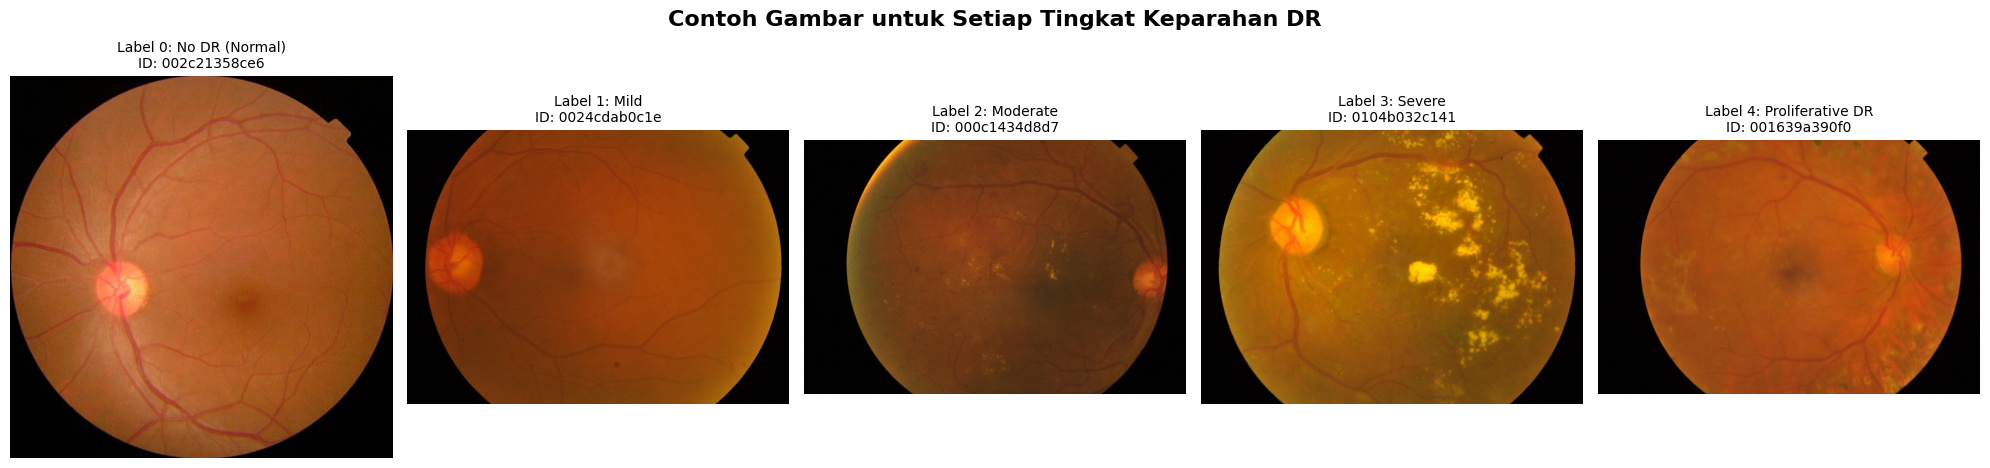

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Contoh Gambar untuk Setiap Tingkat Keparahan DR", fontsize=16, fontweight='bold')

for i in range(5):
    sample = df[df['diagnosis'] == i].iloc[0]

    img_name = f"{sample['id_code']}.png"
    img_path = os.path.join(IMAGE_DIR, img_name)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    axes[i].imshow(img)
    axes[i].set_title(f"Label {i}: {sample['label_name']}\nID: {sample['id_code']}", fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Data Split

In [8]:
train_df, test_val_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    stratify=df['diagnosis']
)

val_df, test_df = train_test_split(
    test_val_df,
    test_size=0.5,
    random_state=42,
    stratify=test_val_df['diagnosis']
)

In [9]:
print(f"Jumlah data Training   : {len(train_df)} gambar ({len(train_df)/len(df)*100:.1f}%)")
print(f"Jumlah data Validation : {len(val_df)} gambar ({len(val_df)/len(df)*100:.1f}%)")
print(f"Jumlah data Testing    : {len(test_df)} gambar ({len(test_df)/len(df)*100:.1f}%)")
print(f"Total data             : {len(train_df) + len(val_df) + len(test_df)} gambar")

Jumlah data Training   : 2563 gambar (70.0%)
Jumlah data Validation : 549 gambar (15.0%)
Jumlah data Testing    : 550 gambar (15.0%)
Total data             : 3662 gambar


# Filter Data Val & Test

In [10]:
IMAGE_SIZE = 224

In [11]:
def crop_and_letterbox(img, tol=10):
    # 1. AUTO-CROP: Membuang sisa background hitam bawaan kamera asli
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    check_axis1 = mask.any(axis=1)
    check_axis0 = mask.any(axis=0)
    
    if check_axis1.any() and check_axis0.any():
        ymin, ymax = np.where(check_axis1)[0][[0, -1]]
        xmin, xmax = np.where(check_axis0)[0][[0, -1]]
        img = img[ymin:ymax+1, xmin:xmax+1]
    
    # 2. LETTERBOX: Menambahkan padding hitam murni agar aspek rasio menjadi 1:1 (Persegi)
    h, w = img.shape[:2]
    max_side = max(h, w)
    
    pad_y = (max_side - h) // 2
    pad_x = (max_side - w) // 2
    pad_y_back = max_side - h - pad_y
    pad_x_back = max_side - w - pad_x
    
    img_square = cv2.copyMakeBorder(
        img, pad_y, pad_y_back, pad_x, pad_x_back,
        borderType=cv2.BORDER_CONSTANT, value=(0, 0, 0)
    )
    
    return img_square
    
def resize_image(img, image_size):
    return cv2.resize(img, (image_size, image_size))

def gaussian_filter(img, image_size):
    img_blur = cv2.GaussianBlur(img, (0, 0), image_size / 30)
    img_ben = cv2.addWeighted(img, 4, img_blur, -4, 128)
    return img_ben

In [12]:
def apply_filter(df, source_dir, output_dir, image_size):
    os.makedirs(output_dir, exist_ok=True)

    for id_code in tqdm(df['id_code'], desc=f"Menerapkan Resize & Filter ({len(df)} data)"):
        src_path = os.path.join(source_dir, f"{id_code}.png")
        dst_path = os.path.join(output_dir, f"{id_code}.png")

        if os.path.exists(dst_path):
            continue

        img = cv2.imread(src_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        img_square = crop_and_letterbox(img, tol=10)
        img_resized = resize_image(img_square, image_size)
        img_ben = gaussian_filter(img_resized, image_size) 

        cv2.imwrite(dst_path, cv2.cvtColor(img_ben, cv2.COLOR_RGB2BGR))

In [13]:
VAL_TEST_DIR = "aptos_data/val_test"
os.makedirs(VAL_TEST_DIR, exist_ok=True)

apply_filter(val_df, IMAGE_DIR, VAL_TEST_DIR, IMAGE_SIZE)
apply_filter(test_df, IMAGE_DIR, VAL_TEST_DIR, IMAGE_SIZE)

Menerapkan Resize & Filter (549 data):   0%|          | 0/549 [00:00<?, ?it/s]

Menerapkan Resize & Filter (550 data):   0%|          | 0/550 [00:00<?, ?it/s]

# Augmentasi Data Train

In [14]:
AUG_CONFIG = {
    "prob_flip_horizontal": 0.5,
    "prob_flip_vertical":   0.3,
    "prob_rotation":        0.7,
    "range_rotation":       (-45, 45),
    "prob_scaling":         0.6,
    "range_scaling":        (0.8, 1.25),
}

In [15]:
def augment_image(image, config=AUG_CONFIG):
    
    # [DI SINI PROSESNYA]: Jadikan persegi murni (1:1) di awal sebelum diutak-atik [source: 1.1.2]
    img_square = crop_and_letterbox(image, tol=10)
    
    max_side = int(img_square.shape[0])
    center = (max_side // 2, max_side // 2)

    # 1. Flip Horizontal
    if np.random.rand() < config["prob_flip_horizontal"]:
        img_square = cv2.flip(img_square, 1)
 
    # 2. Flip Vertikal
    if np.random.rand() < config["prob_flip_vertical"]:
        img_square = cv2.flip(img_square, 0)
        
    # 3. Rotasi Aman (Bebas Potongan Garis Tajam)
    if np.random.rand() < config["prob_rotation"]:
        angle = np.random.uniform(*config["range_rotation"])
        rot_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        img_square = cv2.warpAffine(
            img_square, 
            rot_matrix, 
            (max_side, max_side), 
            borderMode=cv2.BORDER_CONSTANT, 
            borderValue=(0, 0, 0)
        )
        
    # 4. Scaling Aman (Bebas Distorsi Lonjong)
    if np.random.rand() < config["prob_scaling"]:
        scale = np.random.uniform(*config["range_scaling"])
        new_size = int(max_side * scale)
        img_scaled = cv2.resize(img_square, (new_size, new_size))
 
        if scale > 1.0:
            # Zoom In: Potong area tengah
            start_pos = (new_size - max_side) // 2
            img_square = img_scaled[start_pos:start_pos + max_side, start_pos:start_pos + max_side]
            img_square = cv2.resize(img_square, (max_side, max_side))
        else:
            # Zoom Out: Beri padding hitam murni di sisi luar
            pad_val = (max_side - new_size) // 2
            pad_val_back = max_side - new_size - pad_val
            img_square = cv2.copyMakeBorder(
                img_scaled,
                pad_val, pad_val_back,
                pad_val, pad_val_back,
                borderType=cv2.BORDER_CONSTANT,
                value=(0, 0, 0)
            )
    img_square = cv2.resize(img_square, (IMAGE_SIZE, IMAGE_SIZE))        
    # Mengembalikan gambar berwujud persegi murni dengan resolusi penuh yang siap disimpan
    return img_square

In [16]:
BALANCED_DIR = "aptos_data/train_balanced"
os.makedirs(BALANCED_DIR, exist_ok=True)

In [17]:
AUGMENTED_DIR = "aptos_data/augmented_raw"
os.makedirs(AUGMENTED_DIR, exist_ok=True)

def generate_augment(df, original_dir, output_dir, config=AUG_CONFIG, seed=42):
    np.random.seed(seed)

    class_counts_local = df['diagnosis'].value_counts()
    target_count = class_counts_local.max()
    target_class = class_counts_local.idxmax()

    print(f"Target jumlah per kelas: {target_count} (mengikuti kelas {target_class})")
    print(f"Distribusi awal:\n{class_counts_local.sort_index()}\n")

    augmented_rows = []

    for cls in sorted(df['diagnosis'].unique()):
        cls_df = df[df['diagnosis'] == cls].reset_index(drop=True)
        n_existing = len(cls_df)
        n_needed = max(0, target_count - n_existing)

        print(f"Kelas {cls}: {n_existing} data asli, perlu {n_needed} data augmentasi tambahan")
        if n_needed == 0:
            continue

        aug_counter, attempts = 0, 0
        max_attempts = n_needed * 3
        pbar = tqdm(total=n_needed, desc=f"Augmentasi kelas {cls}")

        while aug_counter < n_needed and attempts < max_attempts:
            attempts += 1
            src_row = cls_df.sample(1).iloc[0]
            src_path = os.path.join(original_dir, f"{src_row['id_code']}.png")

            img = cv2.imread(src_path)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            img_aug = augment_image(img, config)

            new_id_code = f"{src_row['id_code']}_aug{aug_counter}"
            dst_path = os.path.join(output_dir, f"{new_id_code}.png")
            cv2.imwrite(dst_path, cv2.cvtColor(img_aug, cv2.COLOR_RGB2BGR))

            augmented_rows.append({"id_code": new_id_code, "diagnosis": cls, "is_augmented": True})
            aug_counter += 1
            pbar.update(1)
        pbar.close()

        if aug_counter < n_needed:
            print(f"  PERINGATAN: hanya {aug_counter}/{n_needed} augmentasi berhasil untuk kelas {cls}.")

    return pd.DataFrame(augmented_rows)


augmented_df = generate_augment(train_df, IMAGE_DIR, AUGMENTED_DIR, config=AUG_CONFIG)


Target jumlah per kelas: 1263 (mengikuti kelas 0)
Distribusi awal:
diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

Kelas 0: 1263 data asli, perlu 0 data augmentasi tambahan
Kelas 1: 259 data asli, perlu 1004 data augmentasi tambahan


Augmentasi kelas 1:   0%|          | 0/1004 [00:00<?, ?it/s]

Kelas 2: 699 data asli, perlu 564 data augmentasi tambahan


Augmentasi kelas 2:   0%|          | 0/564 [00:00<?, ?it/s]

Kelas 3: 135 data asli, perlu 1128 data augmentasi tambahan


Augmentasi kelas 3:   0%|          | 0/1128 [00:00<?, ?it/s]

Kelas 4: 207 data asli, perlu 1056 data augmentasi tambahan


Augmentasi kelas 4:   0%|          | 0/1056 [00:00<?, ?it/s]

# Filter Data Train

In [18]:
def apply_filter_train(df, source_dir, output_dir, image_size, is_augmented=False):
    os.makedirs(output_dir, exist_ok=True)

    for id_code in tqdm(df['id_code'], desc=f"Menerapkan Resize & Filter ({len(df)} data)"):
        src_path = os.path.join(source_dir, f"{id_code}.png")
        dst_path = os.path.join(output_dir, f"{id_code}.png")

        if os.path.exists(dst_path):
            continue

        img = cv2.imread(src_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if is_augmented:
            # Data augmentasi sudah berukuran persegi 224x224 dari fungsi augment_image,
            # jadi langsung diaplikasikan filter Ben Graham tanpa di-crop ulang
            img_ben = gaussian_filter(img, image_size)
        else:
            # Data asli masih mentah (persegi panjang), wajib crop & letterbox dulu
            img_square = crop_and_letterbox(img, tol=10)
            img_resized = resize_image(img_square, image_size)
            img_ben = gaussian_filter(img_resized, image_size)

        cv2.imwrite(dst_path, cv2.cvtColor(img_ben, cv2.COLOR_RGB2BGR))




In [19]:
print("=== Memproses Data Training Asli ===")
apply_filter_train(train_df, IMAGE_DIR, BALANCED_DIR, IMAGE_SIZE, is_augmented=False)

print("\n=== Memproses Data Training Augmentasi ===")
apply_filter_train(augmented_df, AUGMENTED_DIR, BALANCED_DIR, IMAGE_SIZE, is_augmented=True)
balanced_df = pd.concat([
    train_df[['id_code', 'diagnosis']].assign(is_augmented=False),
    augmented_df[['id_code', 'diagnosis', 'is_augmented']]
], ignore_index=True)

print("\n=== Distribusi setelah balancing ===")
print(balanced_df['diagnosis'].value_counts().sort_index())
print(f"Total data training: {len(balanced_df)}")

=== Memproses Data Training Asli ===


Menerapkan Resize & Filter (2563 data):   0%|          | 0/2563 [00:00<?, ?it/s]


=== Memproses Data Training Augmentasi ===


Menerapkan Resize & Filter (3752 data):   0%|          | 0/3752 [00:00<?, ?it/s]


=== Distribusi setelah balancing ===
diagnosis
0    1263
1    1263
2    1263
3    1263
4    1263
Name: count, dtype: int64
Total data training: 6315


In [20]:
# Menentukan folder tempat penyimpanan file CSV
CSV_OUTPUT_DIR = "aptos_data/csv_metadata"
os.makedirs(CSV_OUTPUT_DIR, exist_ok=True)

# Path file tujuan untuk masing-masing dataframe
val_csv_path = os.path.join(CSV_OUTPUT_DIR, "val_data.csv")
test_csv_path = os.path.join(CSV_OUTPUT_DIR, "test_data.csv")
balanced_train_csv_path = os.path.join(CSV_OUTPUT_DIR, "balanced_train_data.csv")

# Menyimpan Dataframe ke file CSV (tanpa menyertakan indeks baris)
val_df.to_csv(val_csv_path, index=False)
test_df.to_csv(test_csv_path, index=False)
balanced_df.to_csv(balanced_train_csv_path, index=False)

print("=== Proses Penyimpanan CSV Selesai ===")
print(f"1. Data Validation disimpan ke : {val_csv_path} ({len(val_df)} baris)")
print(f"2. Data Testing disimpan ke    : {test_csv_path} ({len(test_df)} baris)")
print(f"3. Data Train Balanced ke      : {balanced_train_csv_path} ({len(balanced_df)} baris)")


=== Proses Penyimpanan CSV Selesai ===
1. Data Validation disimpan ke : aptos_data/csv_metadata/val_data.csv (549 baris)
2. Data Testing disimpan ke    : aptos_data/csv_metadata/test_data.csv (550 baris)
3. Data Train Balanced ke      : aptos_data/csv_metadata/balanced_train_data.csv (6315 baris)


In [ ]:
sample_row = val_df.iloc[0]
original_path = os.path.join(IMAGE_DIR, f"{sample_row['id_code']}.png")
ben_graham_path = os.path.join(VAL_TEST_DIR, f"{sample_row['id_code']}.png")

original_img = cv2.imread(original_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

ben_img = cv2.imread(ben_graham_path)
ben_img = cv2.cvtColor(ben_img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(original_img)
axes[0].set_title(f"Original\nID: {sample_row['id_code']}")
axes[0].axis('off')

axes[1].imshow(ben_img)
axes[1].set_title("Setelah Metode Ben Graham (Gaussian Blur)")
axes[1].axis('off')

plt.tight_layout()
plt.show()